In [39]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

PATH = "../results/phase1"
SPECS = {  # instance: (architecture, vCPU, memory GiB)
    "c6i.2xlarge": ("Intel Ice Lake", 8, 16),
    "c7i.1xlarge": ("Intel Sapphire Rapids", 4, 8),
    "c7i.2xlarge": ("Intel Sapphire Rapids", 8, 16),
    "c7i.4xlarge": ("Intel Sapphire Rapids", 16, 32),
    "m7i.2xlarge": ("Intel Sapphire Rapids", 8, 32),
    "r7i.2xlarge": ("Intel Sapphire Rapids", 8, 64),
    "c7a.2xlarge": ("AMD Genoa", 8, 16),
    "c8g.2xlarge": ("ARM Graviton4", 8, 16),
}
METRICS = {  # column: plot label
    "prefill_s": "Prefill time (s)",
    "prefill_ms_tok": "Prefill per token (ms)",
    "decode_s": "Decode time (s)",
    "overhead_s": "Network Overhead (s)",
}
NATURAL = {  # natural mode stops at different output lengths, so compare decode per output token
    "prefill_s": "Prefill time (s)",
    "prefill_ms_tok": "Prefill per token (ms)",
    "tpot_ms": "TPOT (ms)",
    "overhead_s": "Network Overhead (s)",
}
UNITS = {"chat": "", "text": " tok", "image": " img", "audio": " s"}
SHADES = {"chat": "Blues", "text": "Oranges", "image": "Greens", "audio": "Reds"}
SIZES = {"chat": ["short"], "text": ["512", "1024", "3072"], "image": ["1", "2", "4"], "audio": ["10", "40"]}
PALETTE = {f"{m} {s}{UNITS[m]}": c for m in SIZES  # one shade of the modality color per size, darker = bigger
           for s, c in zip(SIZES[m], sns.color_palette(SHADES[m], len(SIZES[m]) + 1)[1:])}


def load(folder):
    """One results folder -> table with setting columns, preferring requests_v2.csv."""
    file = f"{PATH}/{folder}/requests_v2.csv"
    df = pd.read_csv(file if os.path.exists(file) else f"{PATH}/{folder}/requests.csv")
    df["folder"] = folder
    df["instance"] = folder.split("__")[0].split("-")[0]  # drop suffix like -amx
    df["arch"], df["vcpu"], df["memory_gb"] = SPECS[df.instance[0]]
    df["quant"] = folder.split("-")[-1]  # Q8_0, Q4_K_M, f16
    # Old requests.csv lacks these: it ran like v2 natural mode, in one sweep
    df["output_mode"] = df.get("output_mode", "natural")
    df["run_id"] = df.get("run_id", "old")
    df["workload"] = df.modality + " " + df["size"].astype(str) + df.modality.map(UNITS)
    # Compute metrics like benchmark.py
    df["prefill_tok_s"] = df.prompt_tokens * 1000 / df.server_prompt_ms
    df["tpot_ms"] = 1000 / df.decode_tok_s
    df["prefill_s"] = df.server_prompt_ms / 1000
    df["prefill_ms_tok"] = df.server_prompt_ms / df.prompt_tokens  # flat across sizes = linear in tokens
    df["decode_s"] = df.server_predicted_ms / 1000
    df["overhead_s"] = (df.e2e_s - (df.server_prompt_ms + df.server_predicted_ms) / 1000).clip(lower=0)
    return df


def keep(df, mode):
    """Same conditions everywhere: 1 request at a time, one output mode, each folder's most complete sweep."""
    df = df.query(f"status == 'ok' and concurrency == 1 and output_mode == '{mode}'")
    return df[df.run_id == df.groupby("folder").run_id.transform(lambda s: s.mode()[0])]


def plot(df, col, x="index", xlabel="Number of request", metrics=METRICS):
    """Rows: metrics, columns: one setting, color: modality."""
    long = df.melt(id_vars=[col, "modality", x], value_vars=list(metrics), var_name="metric")
    long["metric"] = long.metric.map(metrics)
    long[x] = long[x].astype(str).astype(pd.CategoricalDtype([str(v) for v in sorted(df[x].unique())], ordered=True))  # evenly spaced x ticks
    g = sns.relplot(long, x=x, y="value", hue="modality", row="metric", col=col,
                    kind="line", marker="o", height=2.5, errorbar=None,
                    facet_kws={"sharey": "row", "margin_titles": True})
    g.set_titles(col_template="{col_name}", row_template="")  # setting names on top only
    g.set_axis_labels(xlabel, "")
    for ax, name in zip(g.axes[:, 0], metrics.values()):  # metric names left of the first column
        ax.set_ylabel(name)


def bars(df, col, title, metrics=METRICS):
    """Grouped bars of the median: one row per metric, one group per workload, color: setting."""
    long = df.melt(id_vars=[col, "workload"], value_vars=list(metrics), var_name="metric")
    long["metric"] = long.metric.map(metrics)
    g = sns.catplot(long, x="workload", y="value", hue=col, order=list(PALETTE), row="metric", kind="bar",
                    estimator="median", errorbar=None, palette="Dark2", height=2.6, aspect=4, sharey=False)
    g.set_titles("")
    g.set_axis_labels("Modality", "")
    for ax, name in zip(g.axes.flat, metrics.values()):  # metric names as y labels
        ax.set_ylabel(name)
    g.legend.set_title("")
    g.figure.suptitle(title, y=1.02)


# Per Request Plot
- consant: number of request, modality, concurrency, repeats, prompt token, outputs token, 
- variable: prefill speed or TTFT, decode speed or TPOT, network overhead

## Architecture

In [40]:
ARCH = ["c6i.2xlarge", "c7i.2xlarge", "c7a.2xlarge", "c8g.2xlarge"]
arch = pd.concat([load(f"{i}__Qwen2.5-Omni-3B-Q8_0") for i in ARCH], ignore_index=True)
arch = keep(arch, "fixed")  # c8g only ran fixed mode (always 128 output tokens)
arch.groupby(["arch", "modality"])[list(METRICS)].median()

prefill_s  prefill_ms_tok   decode_s  \
arch                  modality                                         
AMD Genoa             audio     12.384595       10.730500  11.369828   
                      chat       0.215283        7.973444  10.749087   
                      image      9.672196       13.106478  11.072139   
                      text       6.828152        6.546646  11.346553   
ARM Graviton4         audio     38.033872       32.366218   3.438344   
                      chat       0.153853        5.536452   2.936483   
                      image     21.332069       28.749419   3.233390   
                      text      10.647124       10.208173   3.347685   
Intel Ice Lake        audio     32.989885       28.605173  14.298806   
                      chat       0.481125       17.655185   9.498422   
                      image     24.740974       33.352536  10.935324   
                      text      17.405464       16.687885  10.416704   
Intel Sapphire Rapids audio     21.923877       18.946056  10.162327   
                      chat       0.209415        7.724000   9.562979   
                      image     17.471662       23.854479   9.949523   
                      text       8.274703        7.933560  10.164181   

                                overhead_s  
arch                  modality              
AMD Genoa             audio       0.086104  
                      chat        0.002407  
                      image       0.035296  
                      text        0.042751  
ARM Graviton4         audio       0.093711  
                      chat        0.003904  
                      image       0.032720  
                      text        0.019226  
Intel Ice Lake        audio       0.110756  
                      chat        0.003987  
                      image       0.054500  
                      text        0.049993  
Intel Sapphire Rapids audio       0.108531  
                      chat        0.003714  
                      image       0.050747  
                      text        0.052208

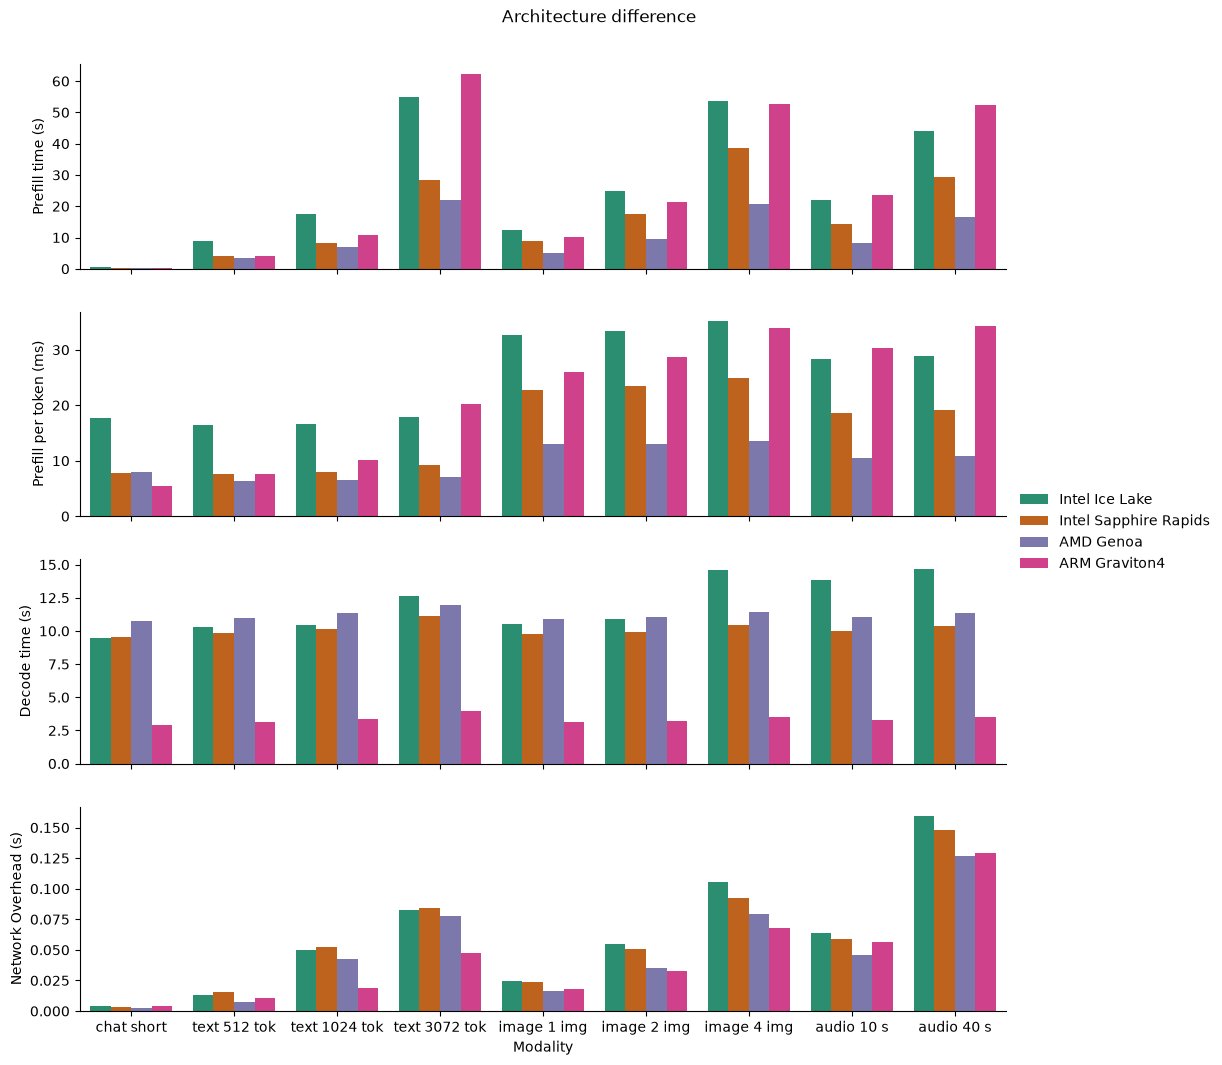

In [41]:
bars(arch, "arch", "Architecture difference")

We compare 4 CPU architectures with 8 vCPU each, running Q8_0 with 128 output tokens per request. We measure prefill time, prefill time per prompt token, decode time and network overhead.
- AMD Genoa has the shortest prefill on every workload, about 2.5× faster per token than Intel Ice Lake.
- ARM Graviton4 decodes about 3× faster than the x86 machines, but its prefill cost per token grows with prompt length. It has the slowest prefill on 3,072-token text.
- Prefill time grows linearly with prompt tokens on the x86 machines, since their prefill cost per token stays flat across sizes.
- Image and audio tokens cost 2 to 3× more to prefill than text tokens, because the vision and audio encoders run first.
- Decode time is about the same for every modality on the same machine, since all modalities share one language model.
- No architecture wins both phases, so the best machine depends on the request. Part of the gap may come from core count, since c7a and c8g have 8 physical cores while c6i and c7i have 4 cores with hyperthreading.

## Memory

In [42]:
MEMORY = ["c7i.2xlarge", "m7i.2xlarge", "r7i.2xlarge"]
memory = pd.concat([load(f"{i}__Qwen2.5-Omni-3B-Q8_0") for i in MEMORY], ignore_index=True)
memory = keep(memory, "natural") 
memory["memory"] = memory.memory_gb.astype(str) + " GiB"
memory.groupby(["memory_gb", "modality"])[list(NATURAL)].median()

prefill_s  prefill_ms_tok    tpot_ms  overhead_s
memory_gb modality                                                  
16        audio     21.962995       18.987215  79.608266    0.098178
          chat       0.211372        7.690778  75.152866    0.004811
          image     17.469264       23.844585  79.065937    0.044968
          text       8.300167        7.957974  80.498232    0.034050
32        audio     22.102410       19.087791  76.549331    0.097027
          chat       0.221379        8.199222  69.551433    0.003983
          image     17.689504       23.929406  73.164087    0.043037
          text       8.330157        7.986728  73.545065    0.032500
64        audio     21.965269       18.963002  74.120906    0.095543
          chat       0.208646        7.726889  68.473882    0.004716
          image     17.507231       23.864548  71.468078    0.042544
          text       8.273266        7.932182  72.866079    0.031452

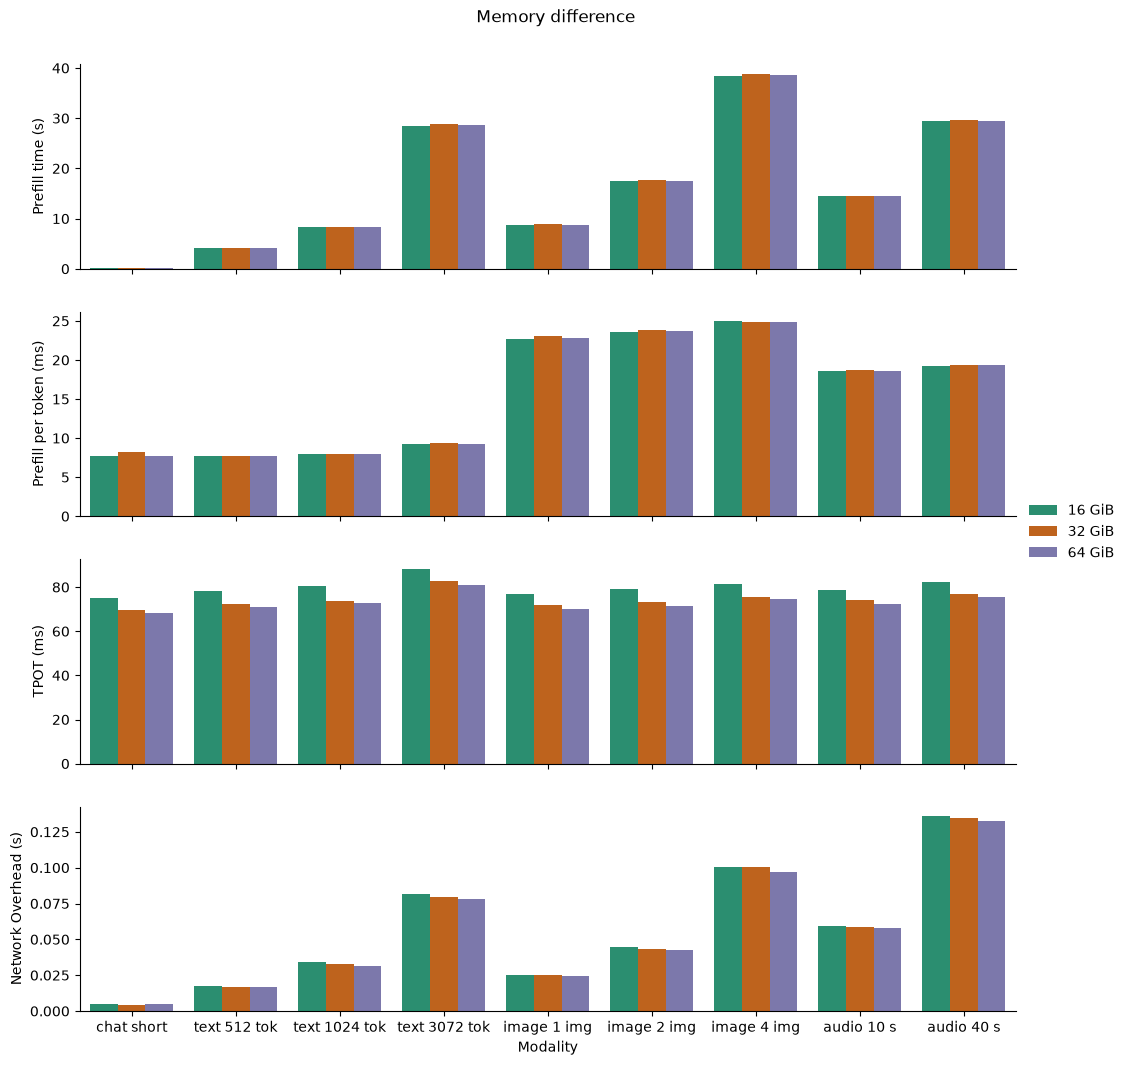

In [43]:
bars(memory, "memory", "Memory difference", NATURAL)

In [44]:
# Peak llama-server RAM (GiB) vs instance RAM, 1 request at a time; one value per workload (summary files)
FOLDERS = [f"{i}__Qwen2.5-Omni-3B-Q8_0" for i in
           ["c7i.1xlarge-q8", "c7i.2xlarge", "c7i.4xlarge-q8", "m7i.2xlarge", "r7i.2xlarge",
            "c6i.2xlarge", "c7a.2xlarge", "c8g.2xlarge"]] + \
          [f"c7i.2xlarge__Qwen2.5-Omni-3B-{q}" for q in ["Q4_K_M", "f16"]]


def peak(folder):
    """One summary file -> peak RAM per workload, with its setup name and instance RAM."""
    file = f"{PATH}/{folder}/summary_v2.csv"
    df = pd.read_csv(file if os.path.exists(file) else f"{PATH}/{folder}/summary.csv")
    # RAM grows during a sweep, so use each sweep's first pass: natural mode (c8g only ran fixed)
    df["output_mode"] = df.get("output_mode", "natural")
    mode = "natural" if (df.output_mode == "natural").any() else "fixed"
    df = df.query("concurrency == 1 and output_mode == @mode")
    instance = folder.split("__")[0].split("-")[0]
    return df.assign(setup=f"{instance} {folder.split('-')[-1]}", capacity_gb=SPECS[instance][2])


ram = pd.concat(map(peak, FOLDERS), ignore_index=True)
ram = ram.groupby("setup", sort=False).agg(capacity_gb=("capacity_gb", "first"), peak_gb=("peak_ram_gb", "max")).reset_index()
ram

,setup,capacity_gb,peak_gb
0,c7i.1xlarge Q8_0,8,6.894268
1,c7i.2xlarge Q8_0,16,10.696941
2,c7i.4xlarge Q8_0,32,10.839081
3,m7i.2xlarge Q8_0,32,10.695408
4,r7i.2xlarge Q8_0,64,10.695492
5,c6i.2xlarge Q8_0,16,7.279903
6,c7a.2xlarge Q8_0,16,7.293461
7,c8g.2xlarge Q8_0,16,10.421356
8,c7i.2xlarge Q4_K_M,16,7.442219
9,c7i.2xlarge f16,16,11.916267


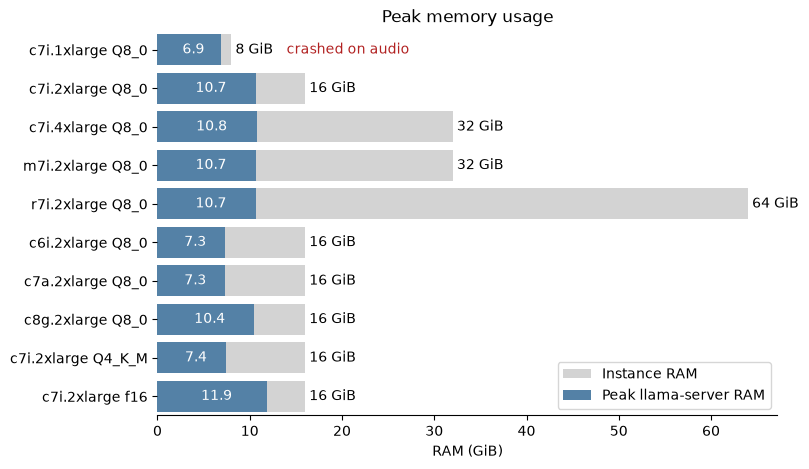

In [45]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(ram, y="setup", x="capacity_gb", color="lightgray", label="Instance RAM", ax=ax)
sns.barplot(ram, y="setup", x="peak_gb", color="steelblue", label="Peak llama-server RAM", ax=ax)
ax.bar_label(ax.containers[0], fmt="%d GiB", padding=3)
ax.bar_label(ax.containers[1], fmt="%.1f", padding=3, color="white", label_type="center")
ax.text(ram.capacity_gb[0] + 6, 0, "crashed on audio", va="center", color="firebrick")  # c7i.1xlarge
ax.set(title="Peak memory usage", xlabel="RAM (GiB)", ylabel="")
ax.legend(loc="lower right")
sns.despine(left=True)

We compare 16, 32 and 64 GiB on Sapphire Rapids with 8 vCPU (c7i, m7i and r7i). These runs stop at the natural output length, so we compare TPOT instead of total decode time. We also record the peak RAM of llama-server on every setup.
- Prefill and network overhead are the same for all memory sizes, and TPOT differs by less than 10%.
- The server peaks at about 11 GiB, so the extra memory on m7i and r7i stays unused.
- The 8 GiB c7i.1xlarge crashed on audio requests, so memory matters only when the model does not fit.
- Q8_0 peaks higher on c7i and c8g (about 10.7 GiB) than on c6i and c7a (about 7.3 GiB), likely because llama.cpp keeps a repacked copy of the weights on those CPUs.
- Memory is a capacity limit and not a speed factor, so the cheapest size that fits is enough.

## vCPU

In [46]:
VCPU = ["c7i.1xlarge-q8", "c7i.2xlarge", "c7i.4xlarge-q8"]
vcpu = pd.concat([load(f"{i}__Qwen2.5-Omni-3B-Q8_0") for i in VCPU], ignore_index=True)
vcpu = keep(vcpu, "natural")
vcpu["vCPU"] = vcpu.vcpu.astype(str) + " vCPU"
vcpu.groupby(["vcpu", "modality"])[list(NATURAL)].median()

prefill_s  prefill_ms_tok     tpot_ms  overhead_s
vcpu modality                                                   
4    audio     23.889803       30.746207  145.651879    0.245314
     chat       0.318777       11.761556  137.914638    0.004006
     image     29.693815       40.948123  143.957295    0.036870
     text      13.949096       13.374013  146.778487    0.032296
8    audio     21.962995       18.987215   79.608266    0.098178
     chat       0.211372        7.690778   75.152866    0.004811
     image     17.469264       23.844585   79.065937    0.044968
     text       8.300167        7.957974   80.498232    0.034050
16   audio      9.684371        8.380020   43.410269    0.091958
     chat       0.127160        4.609185   41.685512    0.006420
     image      7.965820       10.982700   42.402618    0.039053
     text       3.716305        3.563092   43.667047    0.031700

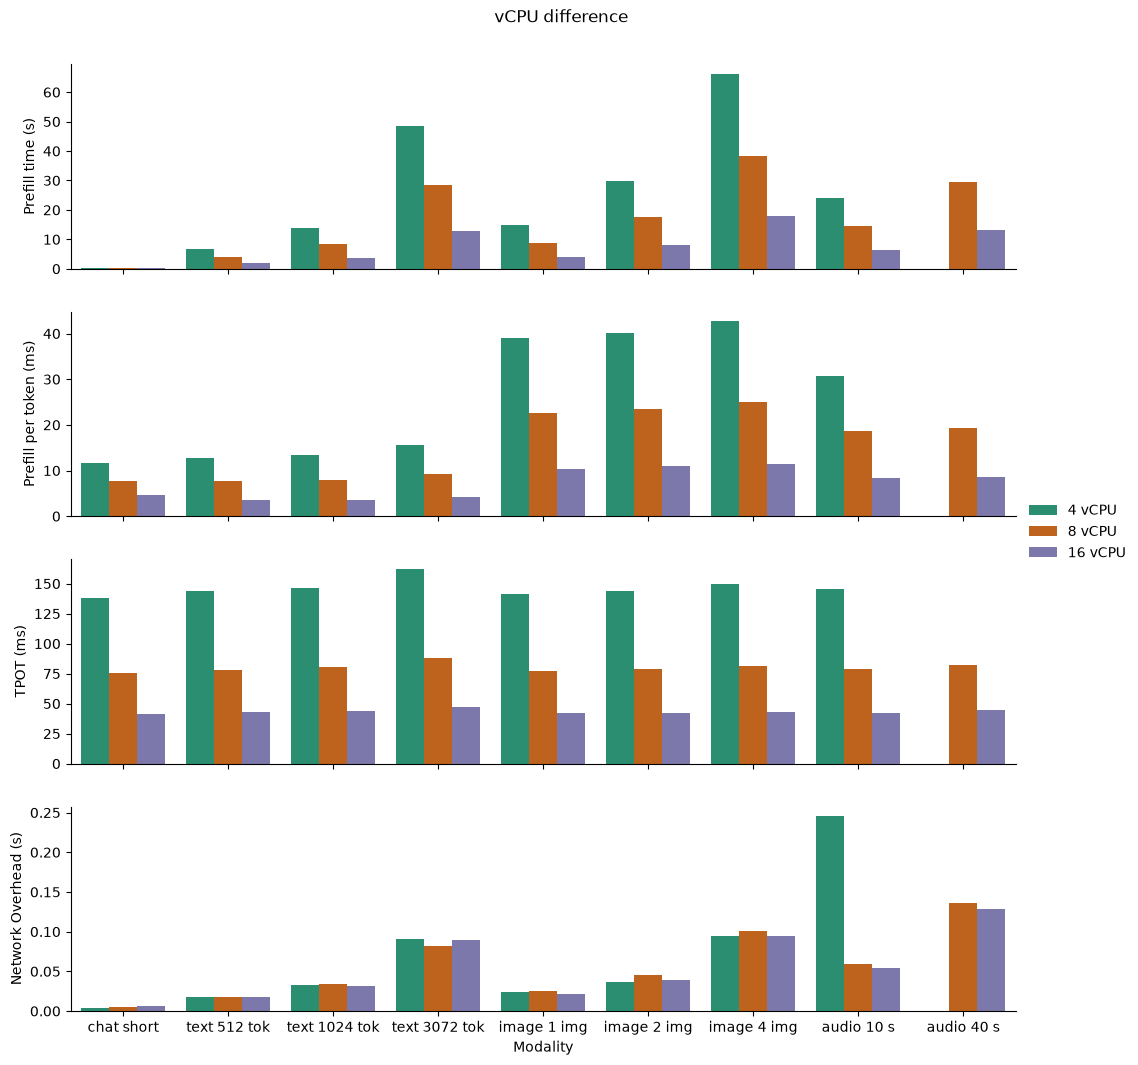

In [47]:
bars(vcpu, "vCPU", "vCPU difference", NATURAL)

We compare 4, 8 and 16 vCPU on Sapphire Rapids (c7i.1xlarge, c7i.2xlarge and c7i.4xlarge). We measure prefill time, prefill time per token, TPOT and network overhead.
- Doubling vCPU roughly halves both prefill and TPOT. TPOT goes from about 145 to 80 to 43 ms.
- TPOT is the same for every modality. Total decode time differs by modality only because the outputs have different lengths.
- Network overhead does not change with vCPU. The spike for audio 10 s on 4 vCPU likely comes from audio preprocessing on a busy CPU.
- 4 vCPU has no audio 40 s result because the server crashed during audio requests.
- The hourly price also doubles with vCPU, so the cost per request stays about the same while latency halves.

## Quantization

In [48]:
QUANT = ["Q4_K_M", "Q8_0", "f16"]
quant = pd.concat([load(f"c7i.2xlarge__Qwen2.5-Omni-3B-{q}") for q in QUANT], ignore_index=True)
quant = keep(quant, "natural") 
quant.groupby(["quant", "modality"])[list(NATURAL)].median()

prefill_s  prefill_ms_tok     tpot_ms  overhead_s
quant  modality                                                   
Q4_K_M audio     20.600856       17.788490   70.386424    0.100355
       chat       0.195180        7.069556   64.957453    0.003585
       image     16.761435       22.723093   67.761600    0.044838
       text       6.757293        6.478709   69.746519    0.032681
Q8_0   audio     21.962995       18.987215   79.608266    0.098178
       chat       0.211372        7.690778   75.152866    0.004811
       image     17.469264       23.844585   79.065937    0.044968
       text       8.300167        7.957974   80.498232    0.034050
f16    audio     29.547972       25.600700  134.703919    0.096495
       chat       0.731857       27.010815  130.023305    0.003984
       image     24.213656       32.590128  132.591250    0.041314
       text      15.177259       14.598925  134.359440    0.034606

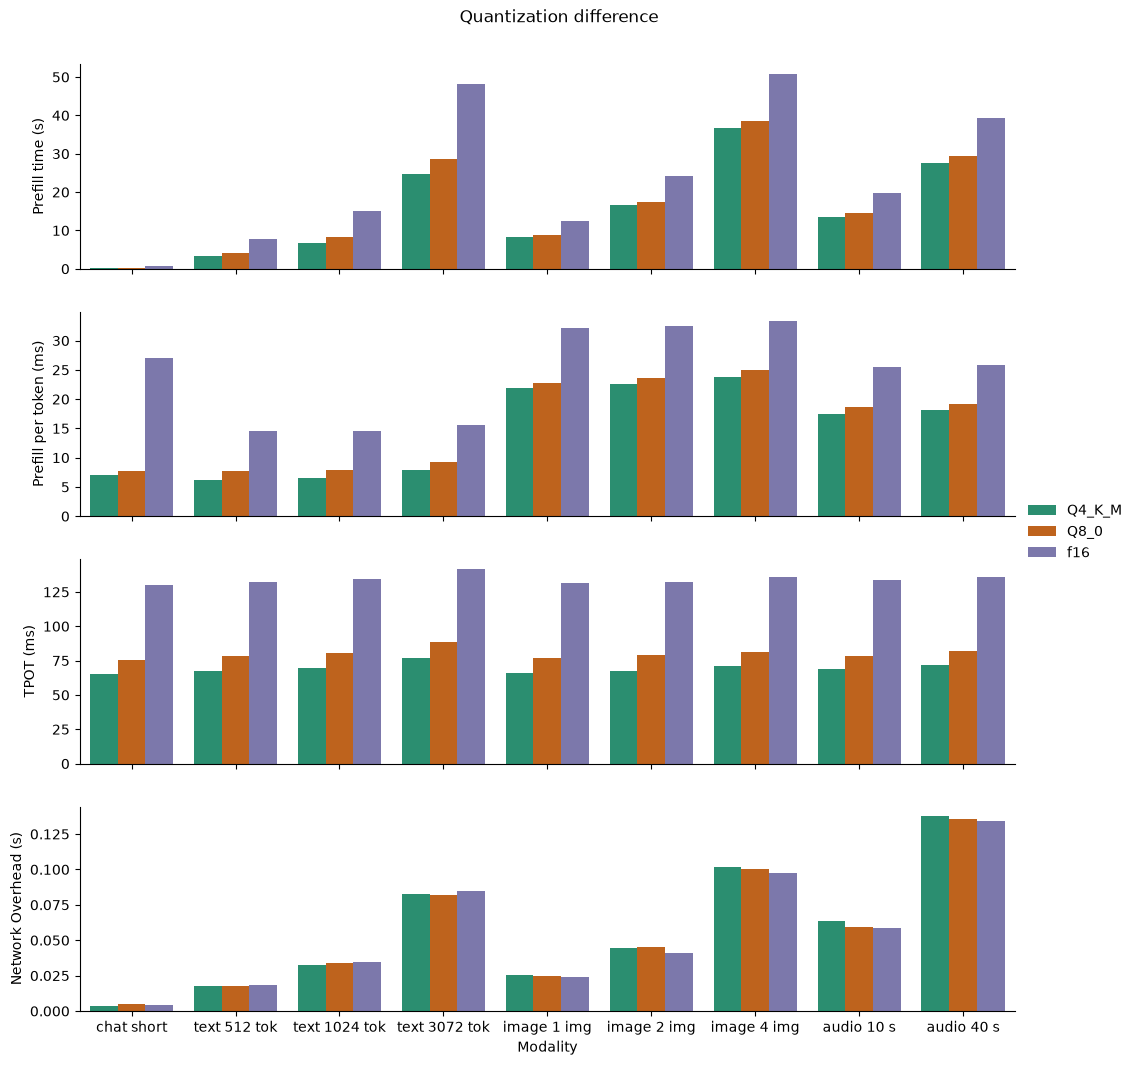

In [49]:
bars(quant, "quant", "Quantization difference", NATURAL)

We compare f16, Q8_0 and Q4_K_M on c7i.2xlarge. We measure prefill time, prefill time per token, TPOT and network overhead. Quality comes from the perplexity runs in [quantization/README.md](quantization/README.md).
- f16 is the slowest in both phases. Its TPOT is about 1.7× that of Q8_0 and its prefill is up to 1.8× slower.
- Q4_K_M is only about 15% faster than Q8_0 in both phases.
- Q8_0 keeps the f16 quality (perplexity 10.71 vs 10.67), while Q4_K_M raises perplexity by 27%.
- Network overhead does not depend on quantization.
- Q8_0 gives the best trade-off between speed and quality.

## Concurrency

In [50]:
CONC = ["c6i.2xlarge", "c7i.2xlarge"]
LATENCY = {  # column: plot label
    "ttft_s": "TTFT (s)",
    "tpot_ms": "TPOT (ms)",
    "queue_s": "Queue wait (s)",
    "e2e_s": "End-to-end latency (s)",
}
conc = pd.concat([load(f"{i}__Qwen2.5-Omni-3B-Q8_0") for i in CONC], ignore_index=True)
# 2 slots, always 128 output tokens: at concurrency 5 and 10 the extra requests queue
conc = conc.query("status == 'ok' and slots == 2 and output_mode == 'fixed'")
conc.groupby(["instance", "concurrency"])[list(LATENCY)].median()

ttft_s     tpot_ms     queue_s       e2e_s
instance    concurrency                                                
c6i.2xlarge 1             22.010009   86.104913    0.054500   35.740200
            2             42.867081   98.120142    0.099611   54.439135
            5             98.127332  113.143870   58.490468  117.041850
            10           194.495051   97.451803  158.422907  218.036873
c7i.2xlarge 1             14.515201   79.000835    0.052759   24.555807
            2             28.997384  101.269661    0.102884   41.795388
            5             63.485760  103.651665   41.990331   82.427632
            10           134.707209  104.054724  119.729265  150.963600

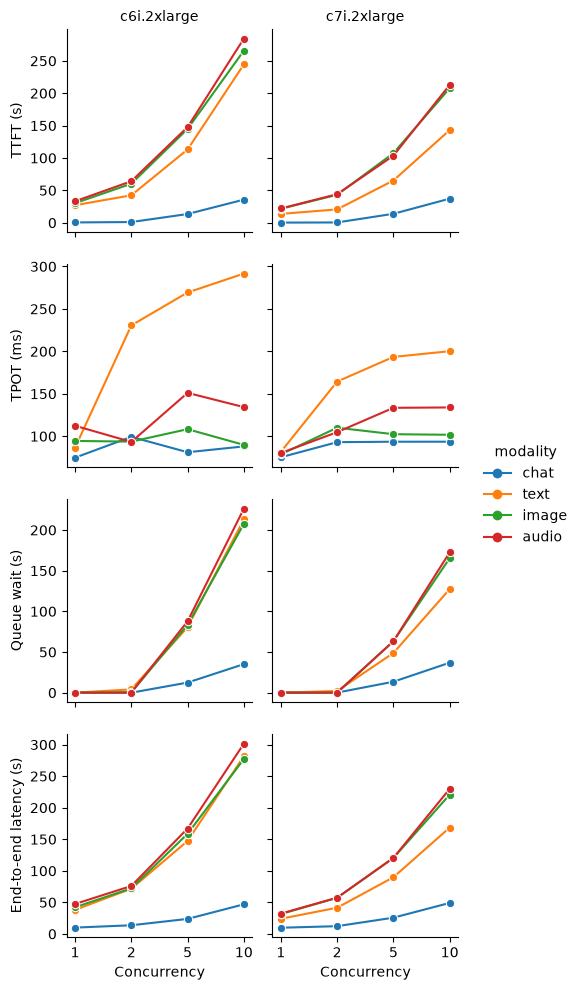

In [51]:
plot(conc, "instance", x="concurrency", xlabel="Concurrency", metrics=LATENCY)

We send 1, 2, 5 and 10 requests at once to a server with 2 slots on Ice Lake and Sapphire Rapids, with 128 output tokens per request. We measure TTFT, TPOT, queue wait and end-to-end latency.
- Queue wait is near zero up to 2 requests, then grows with concurrency because the extra requests wait for a free slot.
- TTFT roughly doubles from 1 to 2 requests, because the two requests share the same CPU.
- Chat also slows down with concurrency, but less in absolute terms because chat requests are short.
- Text TPOT rises the most with concurrency, possibly because the other slot's long prompt is processed between decode steps.
- Sapphire Rapids keeps about 30% lower latency than Ice Lake at every concurrency.

In [52]:
THROUGHPUT = {  # column: plot label
    "req_s": "Throughput (req/s)",
    "out_tok_s": "Throughput (output tok/s)",
}
# Throughput is per workload, so it comes from summary_v2.csv
summary = pd.concat([pd.read_csv(f"{PATH}/{i}__Qwen2.5-Omni-3B-Q8_0/summary_v2.csv").assign(instance=i)
                     for i in CONC], ignore_index=True)
summary = summary.query("slots == 2 and output_mode == 'fixed'")
summary.groupby(["instance", "concurrency"])[list(THROUGHPUT)].median()

req_s  out_tok_s
instance    concurrency                     
c6i.2xlarge 1            0.027944   3.576772
            2            0.036954   4.730167
            5            0.035370   4.527412
            10           0.037119   4.751195
c7i.2xlarge 1            0.040760   5.217299
            2            0.047940   6.136314
            5            0.047760   6.113297
            10           0.047601   6.092886

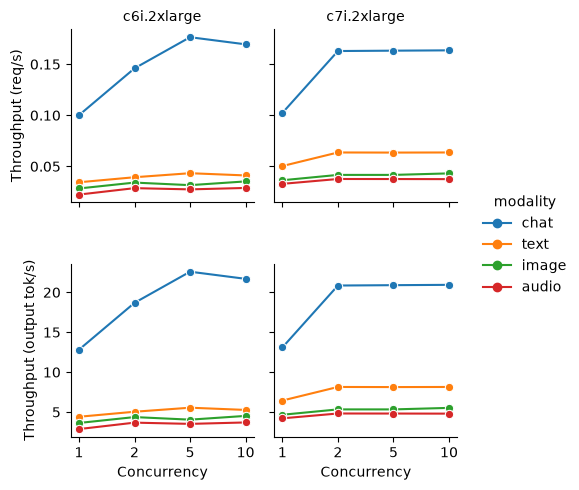

In [53]:
plot(summary, "instance", x="concurrency", xlabel="Concurrency", metrics=THROUGHPUT)

We measure throughput per workload in requests per second and output tokens per second, with the same 2-slot setup.
- Throughput rises 18 to 30% from 1 to 2 requests and stays flat after that.
- Chat gains the most (about 50 to 60%) because it is mostly decode, and decoding two requests together reuses the same weight reads. Prefill-heavy workloads gain little because one prefill already uses the whole CPU.
- More requests on one machine only add waiting, so spreading requests across machines is better than packing them onto one.

## Baseline

# Summary Plot

In [54]:
# (a) Measured end-to-end latency on the 8 vCPU nodes, one dot per request (fixed mode: 128 output tokens).
# Chat is a ~27-token text prompt, so it joins text.
arch["input"] = arch.modality.replace({"chat": "text"})
COLORS = dict(zip(arch.arch.unique(), sns.color_palette("Dark2")))  # same colors as the dot plots

# (b) Where latency goes at each concurrency, 2 slots (mean, so the parts add up to end-to-end latency)
PARTS = {"prefill_s": "Prefill", "decode_s": "Decode", "queue_s": "Queue wait"}
parts = conc.groupby(["arch", "concurrency"])[list(PARTS)].mean().rename(columns=PARTS)

# (c) Throughput at each concurrency
summary["arch"] = summary.instance.map(lambda i: SPECS[i][0])
arch.pivot_table(index="workload", columns="arch", values="e2e_s", aggfunc="median").reindex(list(PALETTE)).round(1)

arch,AMD Genoa,ARM Graviton4,Intel Ice Lake,Intel Sapphire Rapids
workload,,,,
chat short,11.0,3.1,10.0,9.8
text 512 tok,14.4,7.2,19.0,14.0
text 1024 tok,18.2,14.0,27.9,18.5
text 3072 tok,34.1,66.3,67.7,39.7
image 1 img,16.0,13.2,23.1,18.6
image 2 img,20.6,24.6,35.7,27.5
image 4 img,32.0,56.3,68.4,49.1
audio 10 s,19.4,27.0,35.9,24.6
audio 40 s,28.0,56.1,58.9,39.9


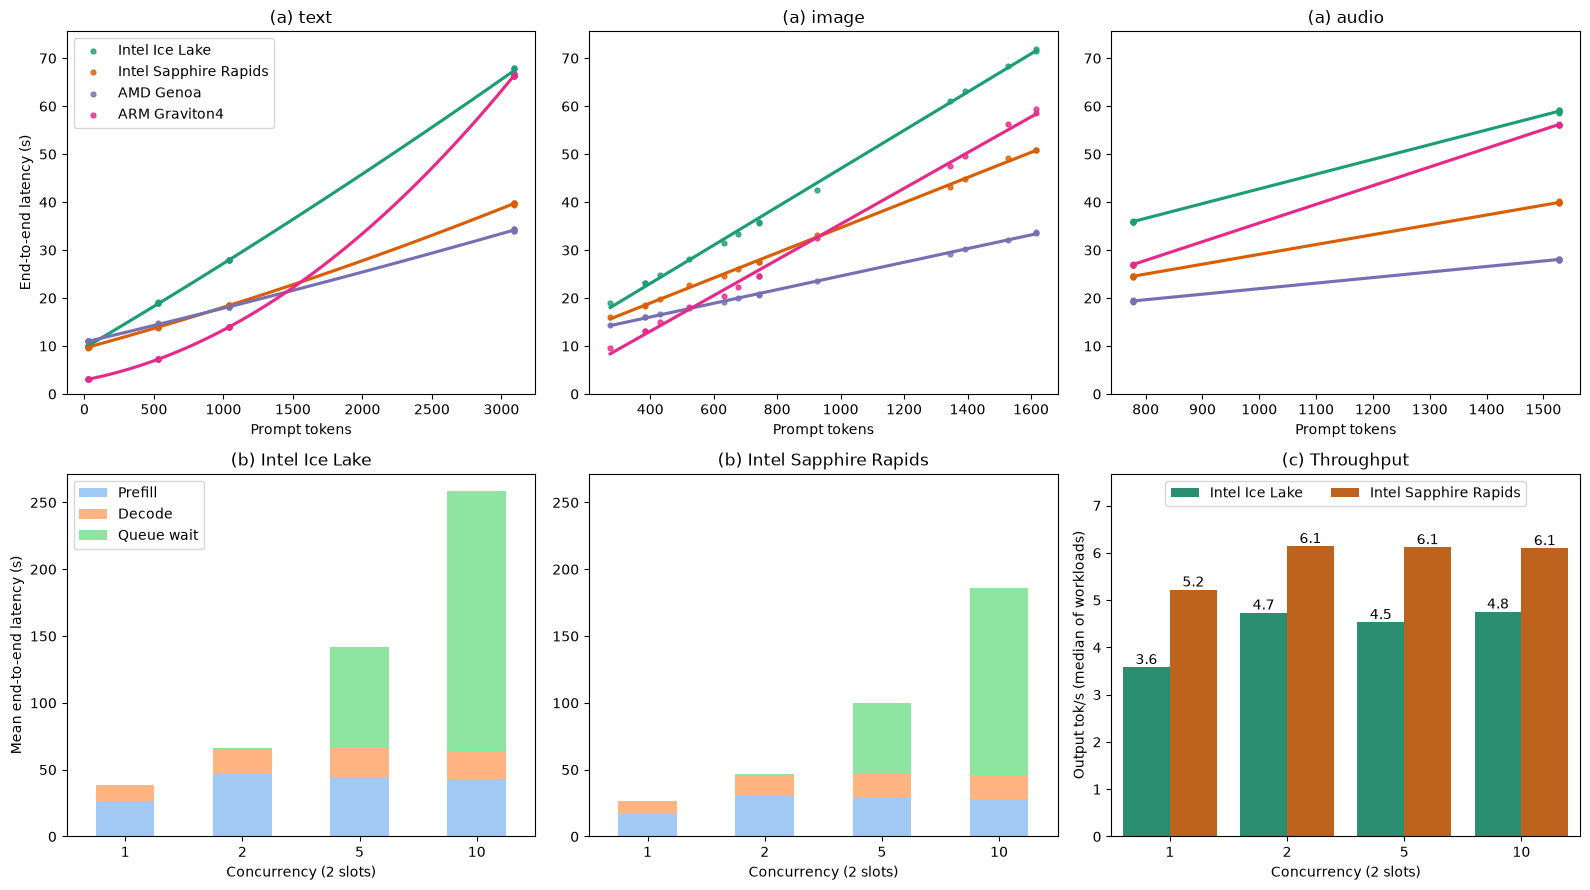

In [55]:
fig, ax = plt.subplot_mosaic([["text", "image", "audio"], ["b1", "b2", "c"]], figsize=(16, 9))
for m in ["text", "image", "audio"]:
    for a, color in COLORS.items():  # regplot is lmplot for one axis
        sns.regplot(arch.query("input == @m and arch == @a"), x="prompt_tokens", y="e2e_s", ci=None,
                    order=2 if m == "text" else 1,  # long text grows faster than linear
                    color=color, label=a, scatter_kws={"s": 12}, ax=ax[m])
    ax[m].set(title=f"(a) {m}", xlabel="Prompt tokens", ylabel="", ylim=(0, arch.e2e_s.max() * 1.05))
ax["text"].set_ylabel("End-to-end latency (s)")
ax["text"].legend()

for k, a in zip(["b1", "b2"], conc.arch.unique()):  # one stacked bar per concurrency
    parts.loc[a].plot.bar(stacked=True, rot=0, color=sns.color_palette("pastel"), legend=k == "b1", ax=ax[k])
    ax[k].set(title=f"(b) {a}", xlabel="Concurrency (2 slots)", ylim=(0, parts.sum(axis=1).max() * 1.05))
ax["b1"].set_ylabel("Mean end-to-end latency (s)")

sns.barplot(summary, x="concurrency", y="out_tok_s", hue="arch", palette=COLORS, estimator="median",
            errorbar=None, ax=ax["c"])
for c in ax["c"].containers:  # not "bars", which would hide the bars() function
    ax["c"].bar_label(c, fmt="%.1f")
ax["c"].set(title="(c) Throughput", xlabel="Concurrency (2 slots)", ylabel="Output tok/s (median of workloads)")
ax["c"].legend(title="", ncols=2, loc="upper center")
ax["c"].margins(y=0.25)  # room for the legend
fig.tight_layout()

# Report Figures

## Figure 1. Architecture and modality
All runs use 8 vCPU, Q8_0 and 128 output tokens per request. Panel (a) leaves out chat, since its ~27-token prompt makes fixed costs dominate the per-token time.

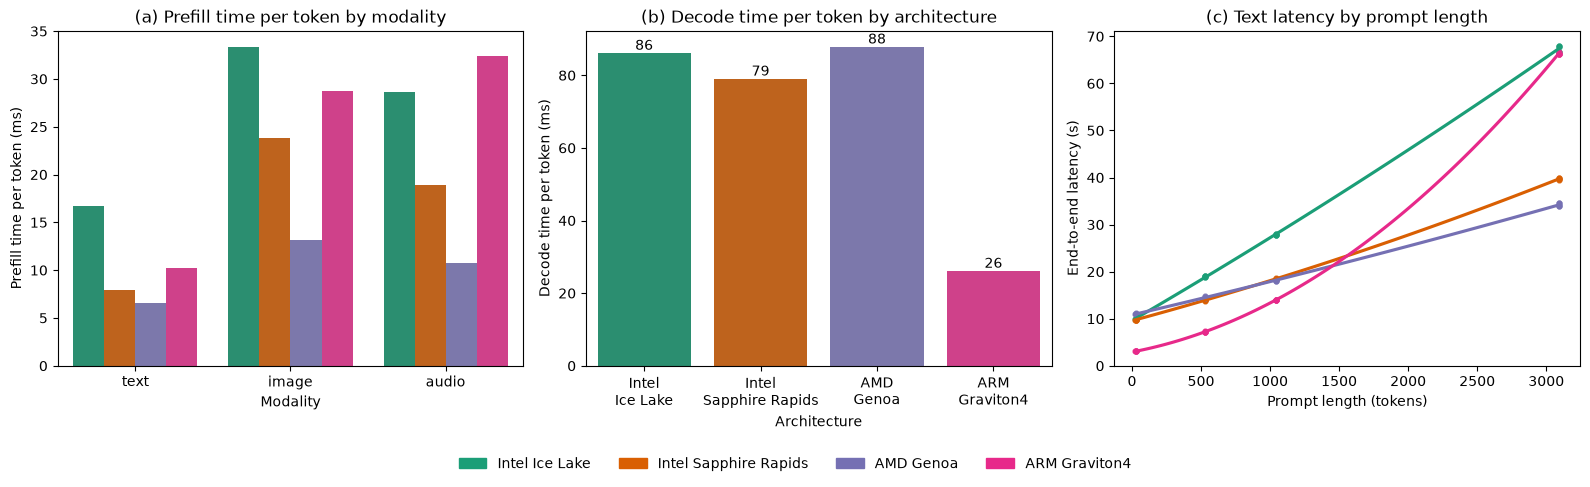

In [56]:
from matplotlib.patches import Patch


def legend_below(fig, handles, ncols, ax=None):
    """Frameless legend under one panel, or under the whole figure, at the same height in every figure."""
    x = 0.5 if ax is None else (ax.get_position().x0 + ax.get_position().x1) / 2
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(x, 0), ncols=ncols, frameon=False)


os.makedirs("figures", exist_ok=True)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) Prefill cost per prompt token, one group per modality
sns.barplot(arch.query("modality != 'chat'"), x="modality", y="prefill_ms_tok", hue="arch", order=["text", "image", "audio"],
            hue_order=list(COLORS), palette=COLORS, estimator="median", errorbar=None, legend=False, ax=ax[0])
ax[0].set(title="(a) Prefill time per token by modality", xlabel="Modality", ylabel="Prefill time per token (ms)")

# (b) Decode cost per output token, all modalities together since they share one language model
sns.barplot(arch, x="arch", y="tpot_ms", hue="arch", order=list(COLORS), palette=COLORS,
            estimator="median", errorbar=None, legend=False, ax=ax[1])
for c in ax[1].containers:
    ax[1].bar_label(c, fmt="%.0f")
ax[1].set_xticks(range(len(COLORS)), [a.replace(" ", "\n", 1) for a in COLORS])  # two-line names
ax[1].set(title="(b) Decode time per token by architecture", xlabel="Architecture", ylabel="Decode time per token (ms)")

# (c) Text end-to-end latency, where the fastest machine changes with prompt length
for a, color in COLORS.items():
    sns.regplot(arch.query("input == 'text' and arch == @a"), x="prompt_tokens", y="e2e_s", order=2, ci=None,
                color=color, scatter_kws={"s": 12}, ax=ax[2])
ax[2].set(title="(c) Text latency by prompt length", xlabel="Prompt length (tokens)", ylabel="End-to-end latency (s)", ylim=(0, None))

fig.tight_layout()
legend_below(fig, [Patch(color=c, label=a) for a, c in COLORS.items()], ncols=4)  # one legend for all panels
fig.savefig("figures/fig1_architecture.png", dpi=200, bbox_inches="tight")

- (a) Genoa has the lowest prefill cost per token for every modality. Image and audio tokens cost 2 to 3× more than text tokens, and the gap depends on the architecture.
- (b) Graviton4 decodes about 3× faster than the x86 machines.
- (c) For text, Graviton4 is the fastest on short prompts and Genoa is the fastest beyond about 1,500 tokens.
- No machine wins every request, which is the main motivation for routing.

## Figure 2. vCPU, memory, quantization and concurrency
All runs use Sapphire Rapids. Panel (a) divides each workload's latency by its latency on the smallest setup (4 vCPU or 16 GiB), so 1 means no change and 0.5 means twice as fast. The vCPU line uses c7i.1xlarge, 2xlarge and 4xlarge, and the memory line uses c7i, m7i and r7i.2xlarge. Panel (b) measures quality with perplexity on wikitext-2, which shows how well the model predicts real text. Lower perplexity means better quality.

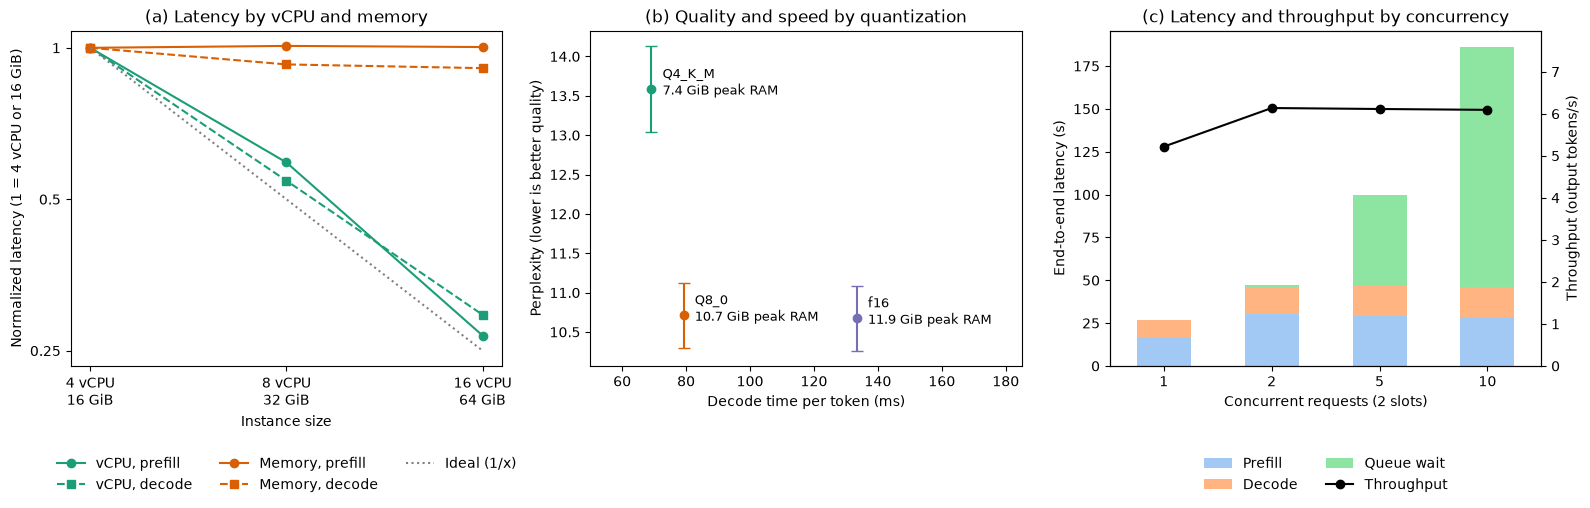

In [57]:
def relative(df, col):
    """Each workload's median over its median at the smallest setting, then the median over workloads."""
    med = df.groupby([col, "workload"])[["prefill_ms_tok", "tpot_ms"]].median()
    return med.div(med.xs(df[col].min(), level=col), level="workload").groupby(col).median()


KNOBS = {"vCPU": relative(vcpu, "vcpu"), "Memory": relative(memory, "memory_gb")}
QCOLORS = dict(zip(QUANT, sns.color_palette("Dark2")))  # same colors as the quantization bars
quality = pd.read_csv("../results/quality/perplexity.csv")
quality["quant"] = quality.model.str.split("-").str[-1]
quality = quality.set_index("quant").join(quant.groupby("quant").tpot_ms.median())
peak = ram.set_index("setup").peak_gb
quality["peak_gb"] = [peak[f"c7i.2xlarge {q}"] for q in quality.index]
SPR = "Intel Sapphire Rapids"

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) Latency relative to the smallest setting, log scales so halving is a straight line
for (name, rel), color in zip(KNOBS.items(), sns.color_palette("Dark2")):
    scale = rel.index / rel.index.min()
    ax[0].plot(scale, rel.prefill_ms_tok, "o-", color=color, label=f"{name}, prefill")
    ax[0].plot(scale, rel.tpot_ms, "s--", color=color, label=f"{name}, decode")
ax[0].plot([1, 4], [1, 0.25], ":", color="gray", label="Ideal (1/x)")
ax[0].set(xscale="log", yscale="log", title="(a) Latency by vCPU and memory",
          xlabel="Instance size", ylabel="Normalized latency (1 = 4 vCPU or 16 GiB)")
ax[0].set_xticks([1, 2, 4], ["4 vCPU\n16 GiB", "8 vCPU\n32 GiB", "16 vCPU\n64 GiB"])
ax[0].set_yticks([1, 0.5, 0.25], ["1", "0.5", "0.25"])
ax[0].minorticks_off()

# (b) Quality vs decode time, lower left is better
for q, r in quality.iterrows():
    ax[1].errorbar(r.tpot_ms, r.ppl, yerr=r.ppl_error, fmt="o", color=QCOLORS[q], capsize=4)
    ax[1].annotate(f"{q}\n{r.peak_gb:.1f} GiB peak RAM", (r.tpot_ms, r.ppl), xytext=(8, -4), textcoords="offset points", fontsize=9)
ax[1].set(title="(b) Quality and speed by quantization", xlabel="Decode time per token (ms)",
          ylabel="Perplexity (lower is better quality)", xlim=(50, 185))

# (c) Where latency goes at each concurrency, with throughput on a second axis
parts.loc[SPR].plot.bar(stacked=True, rot=0, color=sns.color_palette("pastel"), legend=False, ax=ax[2])
ax[2].set(title="(c) Latency and throughput by concurrency", xlabel="Concurrent requests (2 slots)", ylabel="End-to-end latency (s)")
tput = summary.query("arch == @SPR").groupby("concurrency").out_tok_s.median()
twin = ax[2].twinx()
twin.plot(range(len(tput)), tput.values, "ko-", label="Throughput")
twin.set(ylabel="Throughput (output tokens/s)", ylim=(0, tput.max() * 1.3))

fig.tight_layout()
legend_below(fig, ax[0].get_legend_handles_labels()[0], ncols=3, ax=ax[0])
legend_below(fig, ax[2].get_legend_handles_labels()[0] + twin.get_legend_handles_labels()[0], ncols=2, ax=ax[2])
fig.savefig("figures/fig2_factors.png", dpi=200, bbox_inches="tight")

- (a) Doubling vCPU roughly halves both prefill and decode time, close to the ideal line. More memory changes almost nothing.
- (b) Q8_0 keeps the f16 quality at almost the Q4_K_M speed, so it gives the best trade-off.
- (c) Throughput stops growing at 2 requests, which is the slot count. Beyond that, the extra latency is all queue wait.